# Benchmark 1: Pitchfork Bifurcation

Supercritical pitchfork normal form:
$$\dot{u} = f(u, \mu) = -u^3 + \mu u$$

1. Oscillating roots vs. branch-approximating solutions by degree continuation.
2. Convergence of the upper branch $\bar{u}_+(\mu) = \sqrt{\mu}\,\chi_{[0,\infty)}(\mu)$ in the smooth, boundary-singularity, and interior-singularity regimes.

In [7]:
import sys
sys.path.append("..")

import numpy as np
from pce_galerkin import set_plot_style, plot_roots_vs_branches, plot_regime

set_plot_style(usetex=True)

def rhs(u, mu):
    return -u**3 + mu[None, :] * u

def jac(u, mu):
    return (-3.0 * u**2 + mu[None, :])[None, :, :]

def exact_upper(mu):
    return np.sqrt(np.maximum(mu, 0.0))[None, :]

## 1. Oscillating roots and degree continuation

Random coefficient initializations produce oscillating solutions, while degree continuation isolates the branch-approximating solutions.

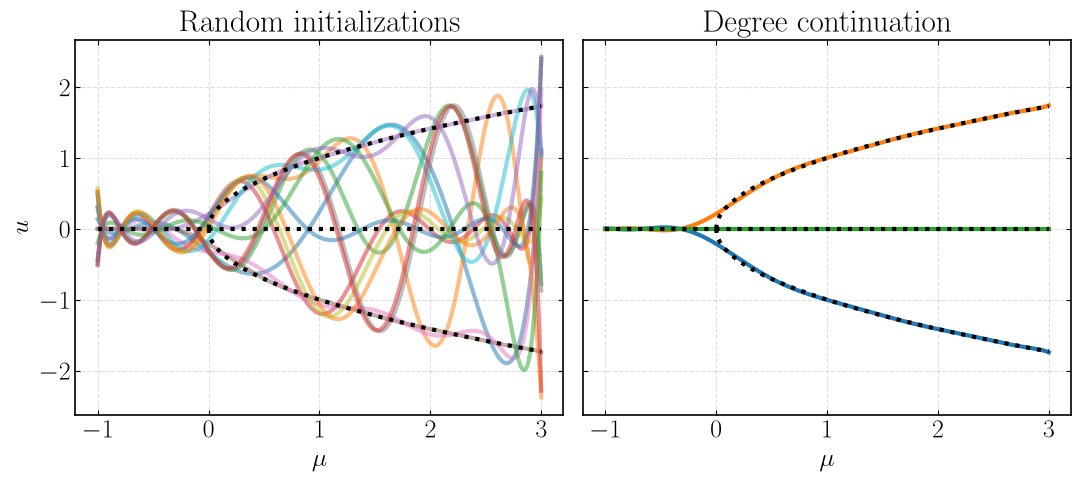

In [8]:
mu_bounds = (-1.0, 3.0)
mu_all = np.linspace(mu_bounds[0], mu_bounds[1], 400)
mu_pos = np.linspace(0.0, mu_bounds[1], 300)

plot_roots_vs_branches(
    rhs,
    jac,
    mu_bounds=mu_bounds,
    exact_curves=[
        (mu_all, np.zeros_like(mu_all)),
        (mu_pos, np.sqrt(mu_pos)),
        (mu_pos, -np.sqrt(mu_pos)),
    ],
    N=10,
    n_samples=20,
    seed=2,
    scale=0.8,
    box=(-2.0, 2.0),
)

## 2. Convergence across regularity regimes

Upper branch $\bar{u}_+(\mu) = \sqrt{\mu}\,\chi_{[0,\infty)}(\mu)$ on three regimes:
- Smooth: $I = [0.2, 1]$
- Boundary singularity: $I = [0, 1]$
- Interior singularity: $I = [-1, 3]$

### 2.1 Smooth regime

Estimated rho (linf): 2.8029


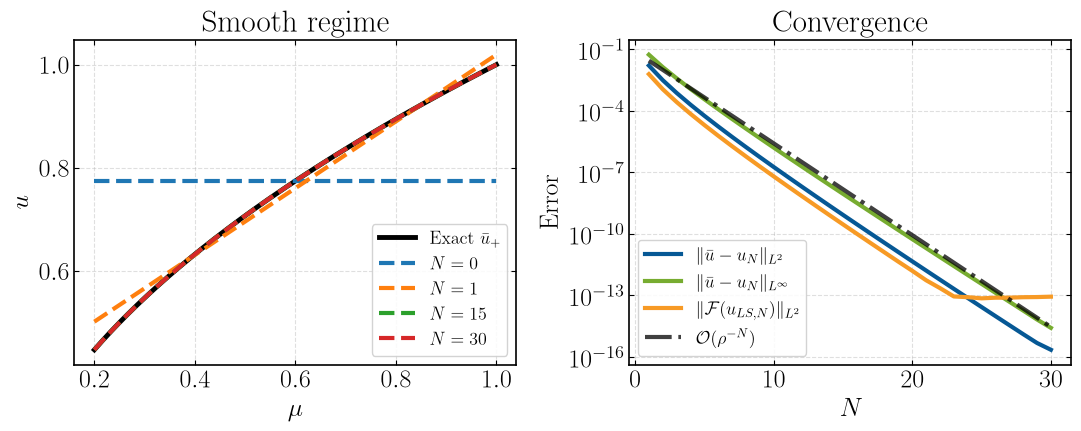

In [9]:
plot_regime(rhs, jac, exact_upper, "Smooth regime", bounds=(0.2, 1.0),
            ref_rates=[(r"$\mathcal{O}(\rho^{-N})$", "-.", None, "linf")],
            u0=[1.0], N_max=30, exact_label=r"Exact $\bar{u}_+$")

### 2.2 Boundary singularity

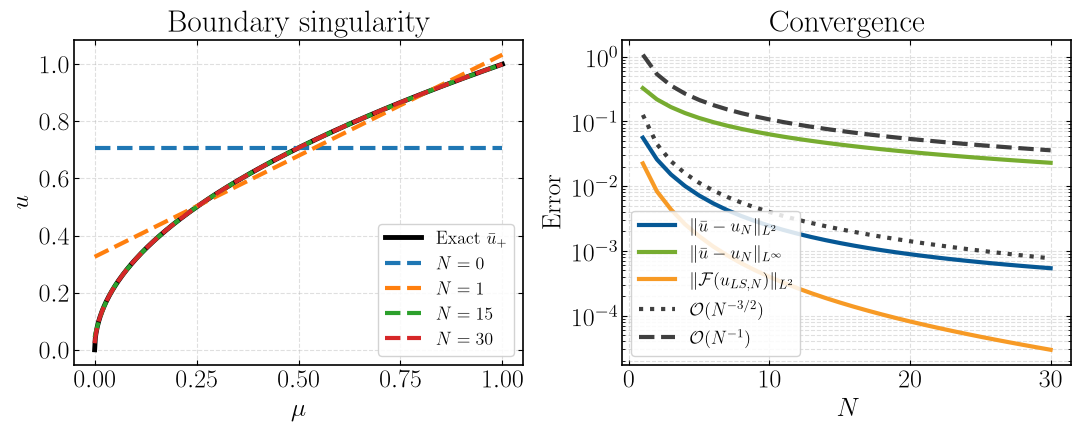

In [10]:
plot_regime(rhs, jac, exact_upper, "Boundary singularity", bounds=(0.0, 1.0),
            ref_rates=[(r"$\mathcal{O}(N^{-3/2})$", ":", lambda N: N**(-1.5), "l2"),
                       (r"$\mathcal{O}(N^{-1})$", "--", lambda N: N**(-1.0), "linf")],
            u0=[1.0], N_max=30, exact_label=r"Exact $\bar{u}_+$")

### 2.3 Interior singularity

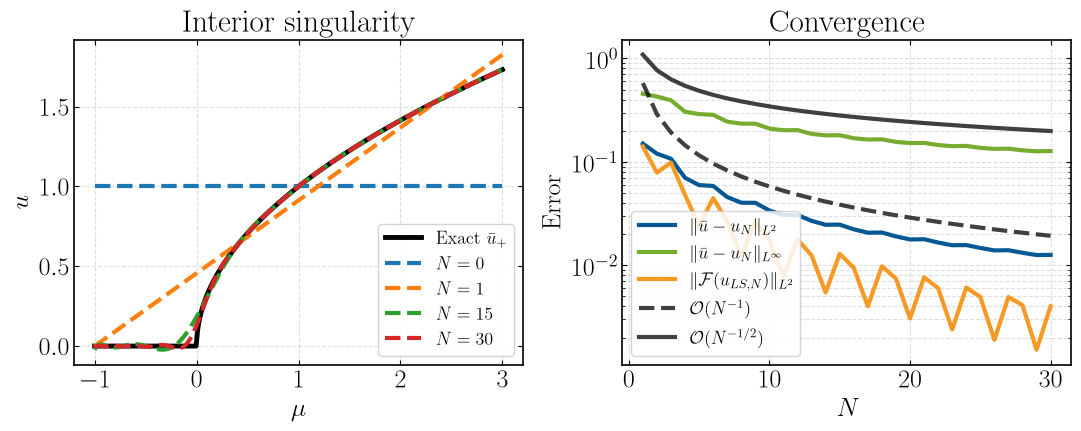

In [11]:
plot_regime(rhs, jac, exact_upper, "Interior singularity", bounds=(-1.0, 3.0),
            ref_rates=[(r"$\mathcal{O}(N^{-1})$", "--", lambda N: N**(-1.0), "l2"), 
               (r"$\mathcal{O}(N^{-1/2})$", "-", lambda N: N**(-0.5), "linf")],
            u0=[1.0], N_max=30, exact_label=r"Exact $\bar{u}_+$")